# Historia 1 — Zajęcia online

Ankietowano **500 studentów**. **350 osób** odpowiedziało, że woli zajęcia online.

**Cel:** obliczyć, jaki może być odsetek takich studentów w całej populacji. Użyjemy **90% przedziału ufności**.

Przedział ufności to zakres, który pomaga nam oszacować wynik dla wszystkich studentów na podstawie ankiety.

### Przygotowanie
Wczytujemy biblioteki potrzebne do obliczeń i wykresów.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

### Krok 1. Zapisujemy dane
Podajemy liczbę ankietowanych i liczbę osób, które wybrały zajęcia online. Python oblicza ich procent.

In [3]:
n1 = 500
online1 = 350
ufnosc1 = 0.90
p1 = online1 / n1

print(f"Udział studentów wybierających online: {p1:.2%}")

Udział studentów wybierających online: 70.00%


### Krok 2. Obliczamy przedział ufności
Program wyznacza dolną i górną granicę. Dzięki temu widzimy, jaki odsetek studentów w całej populacji szacujemy na podstawie ankiety.

In [4]:
z1 = stats.norm.ppf((1 + ufnosc1) / 2)
se1 = np.sqrt(p1 * (1 - p1) / n1)
margines1 = z1 * se1
ci1_dol = p1 - margines1
ci1_gora = p1 + margines1

assert n1 * p1 >= 5 and n1 * (1 - p1) >= 5
print(f"Wartość krytyczna Z: {z1:.4f}")
print(f"Błąd standardowy: {se1:.5f}")
print(f"Margines błędu: ±{margines1:.2%}")
print(f"90% przedział ufności: ({ci1_dol:.2%}; {ci1_gora:.2%})")

Wartość krytyczna Z: 1.6449
Błąd standardowy: 0.02049
Margines błędu: ±3.37%
90% przedział ufności: (66.63%; 73.37%)


### Krok 3. Rysujemy wykres
Środkowa linia pokazuje wynik ankiety. Dwie linie po bokach wskazują granice przedziału. Kolorowy obszar to nasz przedział ufności.

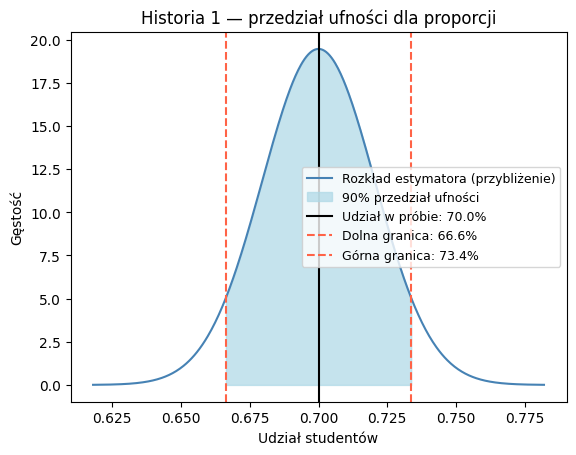

In [5]:
x_wykres1 = np.linspace(p1 - 4 * se1, p1 + 4 * se1, 500)
y_wykres1 = stats.norm.pdf(x_wykres1, loc=p1, scale=se1)

fig, ax = plt.subplots()
ax.plot(x_wykres1, y_wykres1, color="steelblue", label="Rozkład estymatora (przybliżenie)")
ax.fill_between(x_wykres1, y_wykres1,
                where=(x_wykres1 >= ci1_dol) & (x_wykres1 <= ci1_gora),
                color="lightblue", alpha=0.7, label="90% przedział ufności")
ax.axvline(p1, color="black", label=f"Udział w próbie: {p1:.1%}")
ax.axvline(ci1_dol, color="tomato", linestyle="--", label=f"Dolna granica: {ci1_dol:.1%}")
ax.axvline(ci1_gora, color="tomato", linestyle="--", label=f"Górna granica: {ci1_gora:.1%}")
ax.set(title="Historia 1 — przedział ufności dla proporcji", xlabel="Udział studentów", ylabel="Gęstość")
ax.legend(fontsize=9)
plt.show()

### Wniosek
W ankiecie **70% studentów** woli zajęcia online. **90% przedział ufności wynosi około 66,63%–73,37%**. To nasze oszacowanie dla całej populacji. Gdyby powtarzać podobne badanie wiele razy, około 90% takich przedziałów obejmowałoby rzeczywisty odsetek.